# K-means Clustering + PCA — CESA1 / HVGlu3 Complex
**University of Jordan — CESA Project**

This notebook performs:
1. Load merged trajectory (`CESA1_all_backbone.xtc`)
2. Featurize using Cα pairwise distances (every 3rd residue to avoid memory crash)
3. PCA to reduce dimensions
4. Elbow method to find optimal number of clusters
5. K-means clustering
6. Save representative PDB for each cluster
7. Save cluster populations

**Note:** Run with `Python (md_analysis)` kernel

In [2]:
# ============================================================
# CELL 1 — Imports
# ============================================================
%matplotlib inline

import mdtraj as md
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from itertools import combinations

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist

plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
sns.set_style('whitegrid')
print('All imports successful!')

All imports successful!


In [3]:
# ============================================================
# CELL 2 — File paths (absolute paths — same style as RMSD/RMSF)
# ============================================================
from pathlib import Path

RUN_DIR    = Path('/Volumes/SAMSUNG/CESAproject/MD_after_docking/result_CESA1_ClusPro/run')
TOPOLOGY   = RUN_DIR / 'backbone.pdb'
TRAJECTORY = RUN_DIR / 'CESA1_all_backbone.xtc'
OUT_DIR    = RUN_DIR / 'KMeans'

OUT_DIR.mkdir(exist_ok=True)

# Verify files exist
for f in [TOPOLOGY, TRAJECTORY]:
    status = '✓' if f.exists() else '✗ MISSING'
    size   = f'{f.stat().st_size / 1e6:.1f} MB' if f.exists() else ''
    print(f'  {status}  {f.name}  {size}')

  ✓  backbone.pdb  0.7 MB
  ✓  CESA1_all_backbone.xtc  250.8 MB


In [4]:
# ============================================================
# CELL 3 — Load trajectory
# ============================================================

print(f'Loading trajectory...')
traj = md.load(str(TRAJECTORY), top=str(TOPOLOGY))

print(traj)
print(f'\nFrames    : {traj.n_frames}')
print(f'Atoms     : {traj.n_atoms}')
print(f'Residues  : {traj.n_residues}')

# Confirm chain structure
chains = list(traj.topology.chains)
print(f'\nChain structure:')
for chain in chains:
    residues = list(chain.residues)
    print(f'  Chain {chain.index}: {len(residues)} residues '
          f'({residues[0].name}{residues[0].resSeq} → {residues[-1].name}{residues[-1].resSeq})')

Loading trajectory...
<mdtraj.Trajectory with 6996 frames, 9066 atoms, 3022 residues, and unitcells>

Frames    : 6996
Atoms     : 9066
Residues  : 3022

Chain structure:
  Chain 0: 619 residues (MET1 → PRO619)
  Chain 1: 801 residues (ARG252 → VAL1052)
  Chain 2: 801 residues (ARG1053 → VAL1853)
  Chain 3: 801 residues (ARG1854 → VAL2654)


In [5]:
# ============================================================
# CELL 4 — Featurization using Cα pairwise distances
#
# IMPORTANT: Using every 3rd Cα to avoid memory crash
# Full Cα: 3022 residues → 4,564,231 pairs → ~255 GB RAM (impossible)
# Every 3rd: ~1007 residues → ~506,521 pairs → ~28 GB (manageable)
# ============================================================

# Select Cα atoms
ca_indices = traj.topology.select('name CA')
print(f'Total Cα atoms: {len(ca_indices)}')

# Use every 3rd Cα
ca_reduced = ca_indices[::3]
print(f'Reduced Cα atoms (every 3rd): {len(ca_reduced)}')

# Compute pairs
ca_pairs = np.array(list(combinations(ca_reduced, 2)))
print(f'Number of pairs: {len(ca_pairs)}')

# Estimate memory
mem_gb = len(ca_pairs) * traj.n_frames * 8 / 1e9
print(f'Estimated memory: {mem_gb:.1f} GB')

print('\nComputing pairwise distances...')
X = md.compute_distances(traj, ca_pairs)
print(f'Feature matrix shape: {X.shape}  ← (frames × pairs)')
print('Featurization complete!')

Total Cα atoms: 3022
Reduced Cα atoms (every 3rd): 1008
Number of pairs: 507528
Estimated memory: 28.4 GB

Computing pairwise distances...
Feature matrix shape: (6996, 507528)  ← (frames × pairs)
Featurization complete!


Running PCA...
PC1: 40.5%
PC2: 13.9%
PC3: 11.7%
Total (3 PCs): 66.0%


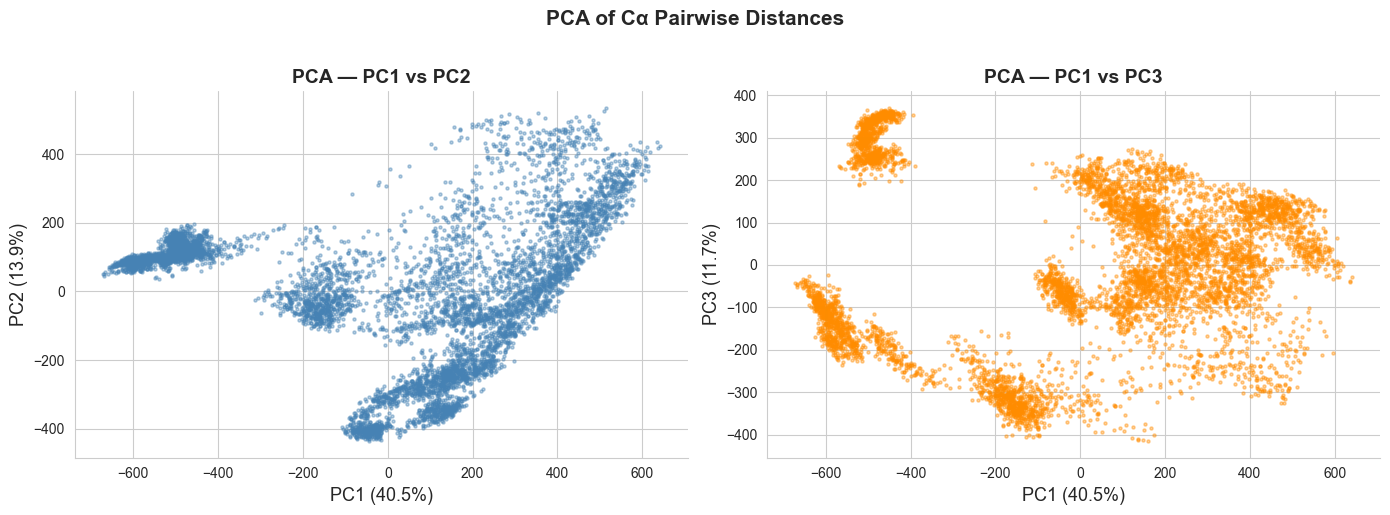

Saved: PCA_plot.png


In [35]:
# ============================================================
# CELL 5 — PCA
# ============================================================

print('Running PCA...')
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

data1 = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3'])

explained = pca.explained_variance_ratio_ * 100
print(f'PC1: {explained[0]:.1f}%')
print(f'PC2: {explained[1]:.1f}%')
print(f'PC3: {explained[2]:.1f}%')
print(f'Total (3 PCs): {sum(explained):.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(data1['PC1'], data1['PC2'], alpha=0.4, s=5, c='steelblue')
axes[0].set_xlabel(f'PC1 ({explained[0]:.1f}%)', fontsize=13)
axes[0].set_ylabel(f'PC2 ({explained[1]:.1f}%)', fontsize=13)
axes[0].set_title('PCA — PC1 vs PC2', fontsize=14, weight='bold')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

axes[1].scatter(data1['PC1'], data1['PC3'], alpha=0.4, s=5, c='darkorange')
axes[1].set_xlabel(f'PC1 ({explained[0]:.1f}%)', fontsize=13)
axes[1].set_ylabel(f'PC3 ({explained[2]:.1f}%)', fontsize=13)
axes[1].set_title('PCA — PC1 vs PC3', fontsize=14, weight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('PCA of Cα Pairwise Distances',
             fontsize=15, weight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / 'PCA_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: PCA_plot.png')

Running elbow method (k=1 to 10)...
  k= 1: inertia=20988.00
  k= 2: inertia=14785.49
  k= 3: inertia=9902.75
  k= 4: inertia=5354.91
  k= 5: inertia=4057.89
  k= 6: inertia=3048.27
  k= 7: inertia=2393.54
  k= 8: inertia=1846.98
  k= 9: inertia=1496.68
  k=10: inertia=1336.56


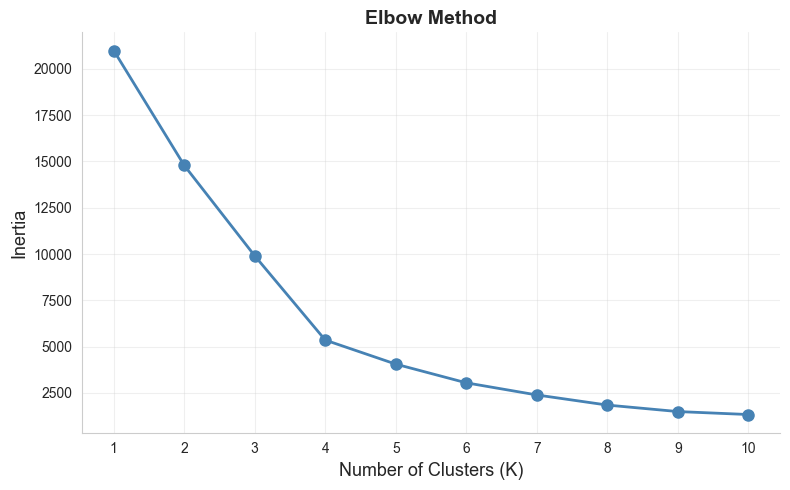

Saved: Elbow_plot.png

>>> Look at the plot and choose K at the elbow bend


In [37]:
# ============================================================
# CELL 6 — Elbow method
# ============================================================

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(data1[['PC1', 'PC2', 'PC3']])

inertia = []
k_range = range(1, 11)

print('Running elbow method (k=1 to 10)...')
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(X_scaled)
    inertia.append(km.inertia_)
    print(f'  k={k:2d}: inertia={km.inertia_:.2f}')

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(k_range), inertia, marker='o', linewidth=2,
        color='steelblue', markersize=8)
ax.set_xlabel('Number of Clusters (K)', fontsize=13)
ax.set_ylabel('Inertia', fontsize=13)
ax.set_title('Elbow Method',
             fontsize=14, weight='bold')
ax.set_xticks(list(k_range))
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / 'Elbow_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: Elbow_plot.png')
print('\n>>> Look at the plot and choose K at the elbow bend')

Running K-means with K=4...

Cluster centers (PC1, PC2, PC3):
  Cluster 1: PC1=-347.572  PC2=47.294  PC3=-227.857  (1714 frames, 24.5%)
  Cluster 2: PC1=371.947  PC2=184.797  PC3=8.336  (1952 frames, 27.9%)
  Cluster 3: PC1=-485.913  PC2=126.911  PC3=299.288  (892 frames, 12.8%)
  Cluster 4: PC1=123.930  PC2=-228.319  PC3=44.074  (2438 frames, 34.8%)


/var/folders/yq/md92lh_s61l6vby7gj6k4xyh0000gp/T/ipykernel_21094/892347481.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap   = plt.cm.get_cmap('tab10', n_clusters)


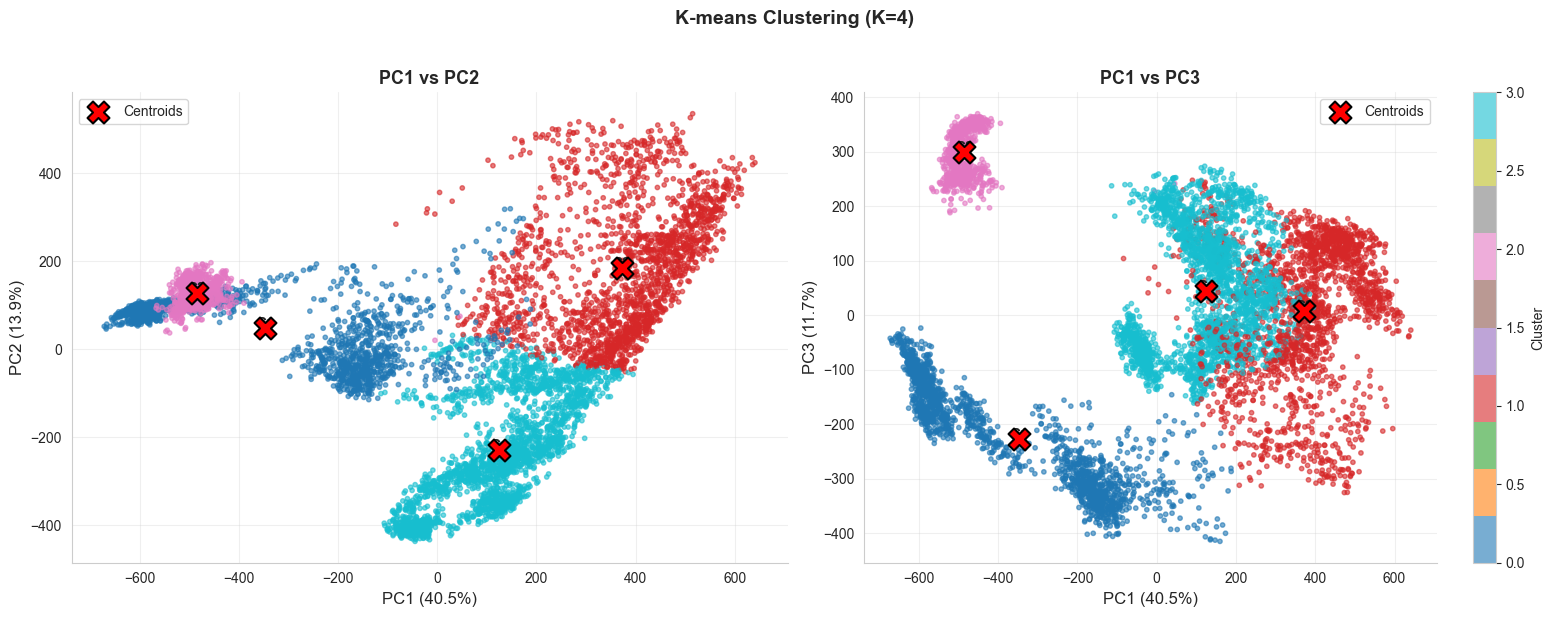

Saved: KMeans_clusters.png


In [39]:
# ============================================================
# CELL 7 — K-means clustering
# *** CHANGE n_clusters BASED ON ELBOW PLOT ***
# ============================================================

n_clusters = 4   # <-- change this after looking at elbow plot

print(f'Running K-means with K={n_clusters}...')

kmeans         = KMeans(n_clusters=n_clusters, random_state=42, n_init=20)
clusters       = kmeans.fit_predict(X_scaled)
data1['Cluster'] = clusters
centers_scaled = kmeans.cluster_centers_
centers        = scaler.inverse_transform(centers_scaled)

print('\nCluster centers (PC1, PC2, PC3):')
for i, c in enumerate(centers):
    count = (clusters == i).sum()
    pct   = count / len(clusters) * 100
    print(f'  Cluster {i+1}: PC1={c[0]:.3f}  PC2={c[1]:.3f}  PC3={c[2]:.3f}  '
          f'({count} frames, {pct:.1f}%)')

# Plot
cmap   = plt.cm.get_cmap('tab10', n_clusters)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (xkey, ykey) in zip(axes, [('PC1','PC2'), ('PC1','PC3')]):
    scatter = ax.scatter(
        data1[xkey], data1[ykey],
        c=data1['Cluster'], cmap='tab10',
        vmin=0, vmax=n_clusters-1,
        s=10, alpha=0.6
    )
    xi = ['PC1','PC2','PC3'].index(xkey)
    yi = ['PC1','PC2','PC3'].index(ykey)
    ax.scatter(
        centers[:, xi], centers[:, yi],
        c='red', s=250, marker='X',
        edgecolors='black', linewidths=1.5,
        label='Centroids', zorder=5
    )
    for i, c in enumerate(centers):
        ax.text(c[xi], c[yi]+0.2, f'C{i+1}',
                fontsize=10, weight='bold', ha='center')
    ax.set_xlabel(f'{xkey} ({explained[xi]:.1f}%)', fontsize=12)
    ax.set_ylabel(f'{ykey} ({explained[yi]:.1f}%)', fontsize=12)
    ax.set_title(f'{xkey} vs {ykey}', fontsize=13, weight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.colorbar(scatter, ax=axes[1], label='Cluster')
plt.suptitle(f'K-means Clustering (K={n_clusters})',
             fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / 'KMeans_clusters.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: KMeans_clusters.png')

In [41]:
# ============================================================
# CELL 8 — Representative frame per cluster + save PDB
# ============================================================

distances      = cdist(X_scaled, centers_scaled)
closest_frames = np.argmin(distances, axis=0)

print('Representative frames (closest to centroid):')
for i, frame in enumerate(closest_frames):
    count = (clusters == i).sum()
    pct   = count / len(clusters) * 100
    print(f'  Cluster {i+1}: frame {frame}  ({count} frames, {pct:.1f}% of trajectory)')

# Save PDB files
pdb_dir = OUT_DIR / 'pdbs'
pdb_dir.mkdir(exist_ok=True)

print('\nSaving representative PDB files...')
for i, frame in enumerate(closest_frames):
    output_name = str(pdb_dir / f'cluster_{i+1}_frame_{frame}.pdb')
    traj[frame].save_pdb(output_name)
    print(f'  Saved: cluster_{i+1}_frame_{frame}.pdb')

print(f'\nAll PDB files saved in {pdb_dir}')

Representative frames (closest to centroid):
  Cluster 1: frame 25  (1714 frames, 24.5% of trajectory)
  Cluster 2: frame 5407  (1952 frames, 27.9% of trajectory)
  Cluster 3: frame 2198  (892 frames, 12.8% of trajectory)
  Cluster 4: frame 3943  (2438 frames, 34.8% of trajectory)

Saving representative PDB files...
  Saved: cluster_1_frame_25.pdb
  Saved: cluster_2_frame_5407.pdb
  Saved: cluster_3_frame_2198.pdb
  Saved: cluster_4_frame_3943.pdb

All PDB files saved in /Volumes/SAMSUNG/CESAproject/MD_after_docking/result_CESA1_ClusPro/run/KMeans/pdbs


Cluster populations:
 Cluster  Population  Percentage
       1        1714       24.50
       2        1952       27.90
       3         892       12.75
       4        2438       34.85


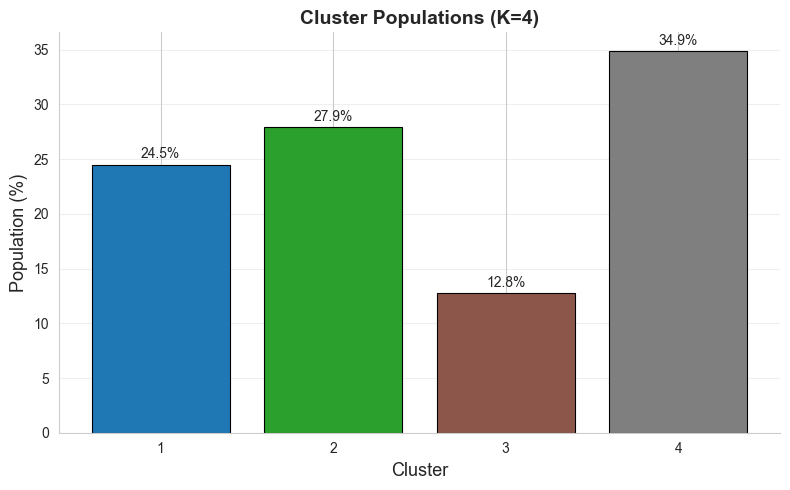


All outputs saved to: /Volumes/SAMSUNG/CESAproject/MD_after_docking/result_CESA1_ClusPro/run/KMeans
  PCA_plot.png
  Elbow_plot.png
  KMeans_clusters.png
  cluster_populations.png
  cluster_populations.csv
  PCA_clusters.csv
  pdbs/cluster_N_frame_M.pdb


In [43]:
# ============================================================
# CELL 9 — Cluster populations
# ============================================================

population = data1['Cluster'].value_counts().sort_index()

population_df = pd.DataFrame({
    'Cluster'   : population.index + 1,
    'Population': population.values,
    'Percentage': (population.values / len(data1) * 100).round(2)
})

print('Cluster populations:')
print(population_df.to_string(index=False))

# Bar plot
fig, ax = plt.subplots(figsize=(8, 5))
colors_bar = [plt.cm.tab10(i / n_clusters) for i in range(n_clusters)]
bars = ax.bar(
    population_df['Cluster'],
    population_df['Percentage'],
    color=colors_bar, edgecolor='black', linewidth=0.8
)

# Add percentage labels on bars
for bar, pct in zip(bars, population_df['Percentage']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xlabel('Cluster', fontsize=13)
ax.set_ylabel('Population (%)', fontsize=13)
ax.set_title(f'Cluster Populations (K={n_clusters})',
             fontsize=14, weight='bold')
ax.set_xticks(population_df['Cluster'])
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / 'cluster_populations.png', dpi=300, bbox_inches='tight')
plt.show()

# Save CSVs
population_df.to_csv(OUT_DIR / 'cluster_populations.csv', index=False)
data1.to_csv(OUT_DIR / 'PCA_clusters.csv', index=False)

print('\nAll outputs saved to:', OUT_DIR)
print('  PCA_plot.png')
print('  Elbow_plot.png')
print('  KMeans_clusters.png')
print('  cluster_populations.png')
print('  cluster_populations.csv')
print('  PCA_clusters.csv')
print('  pdbs/cluster_N_frame_M.pdb')

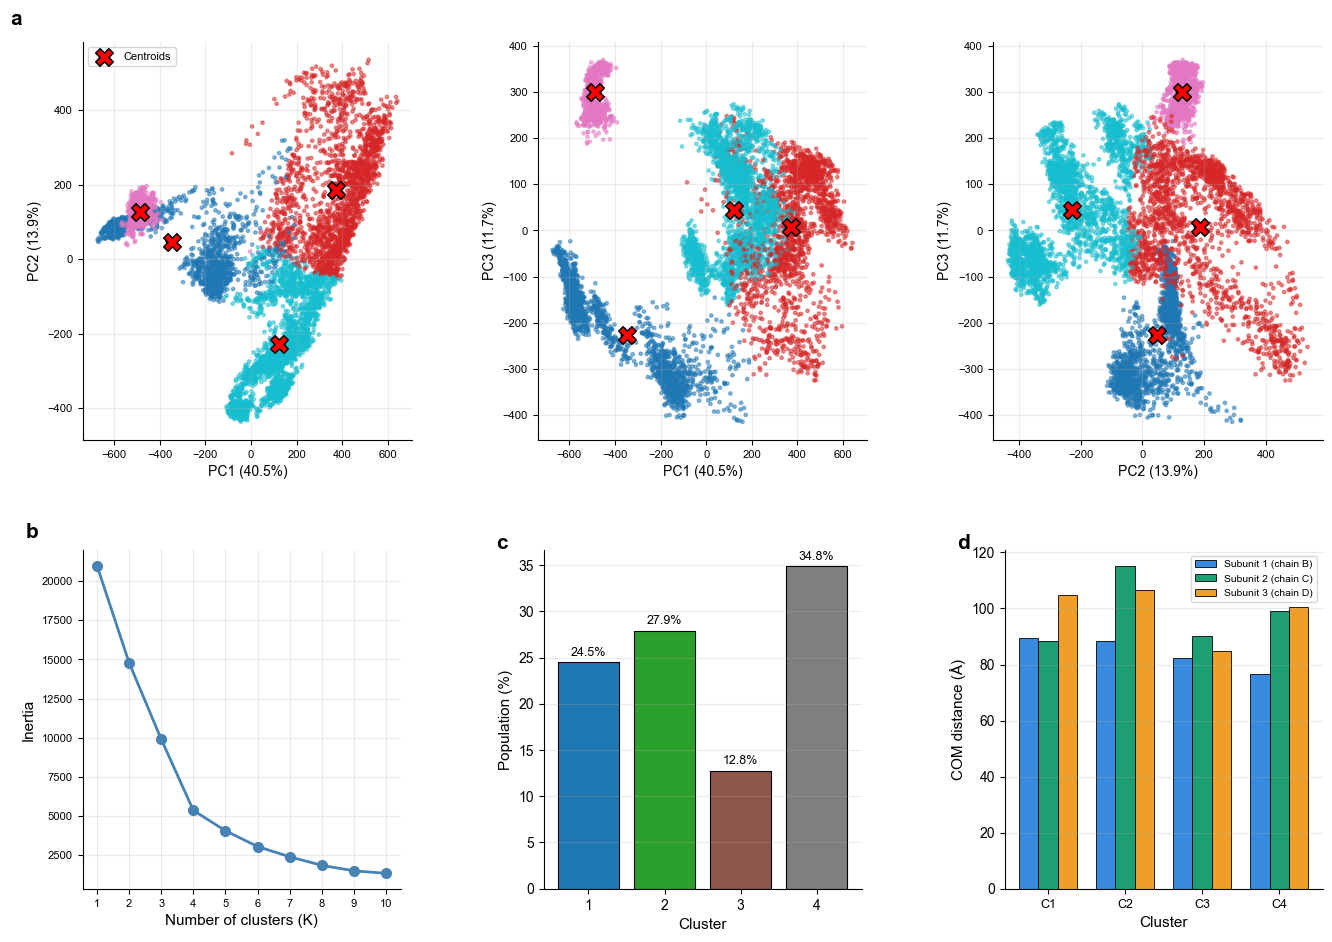

Saved: /Volumes/SAMSUNG/CESAproject/MD_after_docking/CESA1/result_CESA1_ClusPro/run/KMeans/Fig4_combined_4panel_v2.png


In [14]:
# ============================================================
# CELL — Combined figure: 3 PCA projections (a), elbow (b),
# populations (c), COM distance (d)
# Panel (a) shows PC1-PC2, PC1-PC3, PC2-PC3 because all three PCs
# contribute meaningfully to cluster separation (between/within
# variance ratios: PC1=8.16, PC2=3.22, PC3=4.80) — none can be dropped
# without losing real separation information.
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from pathlib import Path
from matplotlib import rcParams

rcParams['font.family']  = 'Arial'
rcParams['pdf.fonttype'] = 42

KMEANS_DIR = Path('/Volumes/SAMSUNG/CESAproject/MD_after_docking/CESA1/result_CESA1_ClusPro/run/KMeans')
RUN_DIR    = KMEANS_DIR.parent
COM_CSV    = RUN_DIR / 'ContactMap' / 'hvglu3_com_distance_by_cluster.csv'

n_clusters = 4
cluster_colors = [plt.cm.tab10(i / n_clusters) for i in range(n_clusters)]

data1     = pd.read_csv(KMEANS_DIR / 'PCA_clusters.csv')
explained = [40.5, 13.9, 11.7]   # PC1, PC2, PC3 percent variance explained — update if different
centers   = data1.groupby('Cluster')[['PC1', 'PC2', 'PC3']].mean().values
pc_idx    = {'PC1': 0, 'PC2': 1, 'PC3': 2}

fig = plt.figure(figsize=(16, 11))
outer = gridspec.GridSpec(2, 1, height_ratios=[1, 0.85], hspace=0.30)

# ══════════════════════════════════════════════
# Top row — Panel (a): three pairwise PCA projections
# ══════════════════════════════════════════════
top = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[0], wspace=0.38)
pc_pairs = [('PC1', 'PC2'), ('PC1', 'PC3'), ('PC2', 'PC3')]

for j, (xkey, ykey) in enumerate(pc_pairs):
    ax = fig.add_subplot(top[j])
    xi, yi = pc_idx[xkey], pc_idx[ykey]
    ax.scatter(
        data1[xkey], data1[ykey],
        c=data1['Cluster'], cmap='tab10',
        vmin=0, vmax=n_clusters - 1,
        s=6, alpha=0.5
    )
    ax.scatter(
        centers[:, xi], centers[:, yi],
        c='red', s=160, marker='X',
        edgecolors='black', linewidths=1.1,
        label='Centroids' if j == 0 else None, zorder=5
    )
    for i, c in enumerate(centers):
        ax.text(c[xi], c[yi], f'C{i+1}', fontsize=8, weight='bold',
                ha='center', va='center')

    ax.set_xlabel(f'{xkey} ({explained[xi]}%)', fontsize=10)
    ax.set_ylabel(f'{ykey} ({explained[yi]}%)', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=8)
    if j == 0:
        ax.legend(fontsize=8, loc='upper left')
        ax.text(-0.22, 1.08, 'a', transform=ax.transAxes,
                fontsize=15, weight='bold', va='top')

# ══════════════════════════════════════════════
# Bottom row — Panels (b) elbow, (c) populations, (d) COM distance
# ══════════════════════════════════════════════
bottom = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[1], wspace=0.45)

# Panel (b) — Elbow plot (rebuilt natively from real inertia values)
ax_b = fig.add_subplot(bottom[0])
k_range = list(range(1, 11))
inertia = [20988.00, 14785.49, 9902.75, 5354.91, 4057.89,
           3048.27, 2393.54, 1846.98, 1496.68, 1336.56]

ax_b.plot(k_range, inertia, marker='o', linewidth=2,
          color='steelblue', markersize=7)
ax_b.set_xlabel('Number of clusters (K)', fontsize=11)
ax_b.set_ylabel('Inertia', fontsize=11)
ax_b.set_xticks(k_range)
ax_b.tick_params(labelsize=8)
ax_b.grid(True, alpha=0.25)
ax_b.spines['top'].set_visible(False)
ax_b.spines['right'].set_visible(False)
ax_b.text(-0.18, 1.08, 'b', transform=ax_b.transAxes,
          fontsize=15, weight='bold', va='top')

# Panel (c) — Cluster population bar chart (rebuilt natively)
ax_c = fig.add_subplot(bottom[1])
population = data1['Cluster'].value_counts().sort_index()
pct = (population.values / len(data1) * 100)

bars = ax_c.bar(
    population.index + 1, pct,
    color=cluster_colors, edgecolor='black', linewidth=0.8
)
for bar, p in zip(bars, pct):
    ax_c.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
              f'{p:.1f}%', ha='center', va='bottom', fontsize=9)

ax_c.set_xlabel('Cluster', fontsize=11)
ax_c.set_ylabel('Population (%)', fontsize=11)
ax_c.set_xticks(population.index + 1)
ax_c.spines['top'].set_visible(False)
ax_c.spines['right'].set_visible(False)
ax_c.grid(axis='y', alpha=0.25)
ax_c.text(-0.15, 1.05, 'c', transform=ax_c.transAxes,
          fontsize=15, weight='bold', va='top')

# Panel (d) — HvGLU3-to-subunit COM distance by cluster
ax_d = fig.add_subplot(bottom[2])
com_df = pd.read_csv(COM_CSV)
com_df = com_df.set_index('Cluster') if 'Cluster' in com_df.columns else com_df.set_index(com_df.columns[0])

x = np.arange(n_clusters)
width = 0.25
subunit_cols = [c for c in com_df.columns if 'subunit' in c.lower()]
subunit_labels = ['Subunit 1 (chain B)', 'Subunit 2 (chain C)', 'Subunit 3 (chain D)']
subunit_face_colors = ['#378ADD', '#1D9E75', '#EF9F27']

for i, (col, lab, col_color) in enumerate(zip(subunit_cols, subunit_labels, subunit_face_colors)):
    ax_d.bar(x + (i - 1) * width, com_df[col].values, width,
             label=lab, color=col_color, edgecolor='black', linewidth=0.6)

ax_d.set_xlabel('Cluster', fontsize=11)
ax_d.set_ylabel('COM distance (Å)', fontsize=11)
ax_d.set_xticks(x)
ax_d.set_xticklabels([f'C{i+1}' for i in range(n_clusters)], fontsize=9)
ax_d.legend(fontsize=7.5, loc='upper right')
ax_d.spines['top'].set_visible(False)
ax_d.spines['right'].set_visible(False)
ax_d.grid(axis='y', alpha=0.25)
ax_d.text(-0.15, 1.05, 'd', transform=ax_d.transAxes,
          fontsize=15, weight='bold', va='top')

out_path = KMEANS_DIR / 'Fig4_combined_4panel_v2.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(KMEANS_DIR / 'Fig4_combined_4panel_v2.pdf', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved: {out_path}')

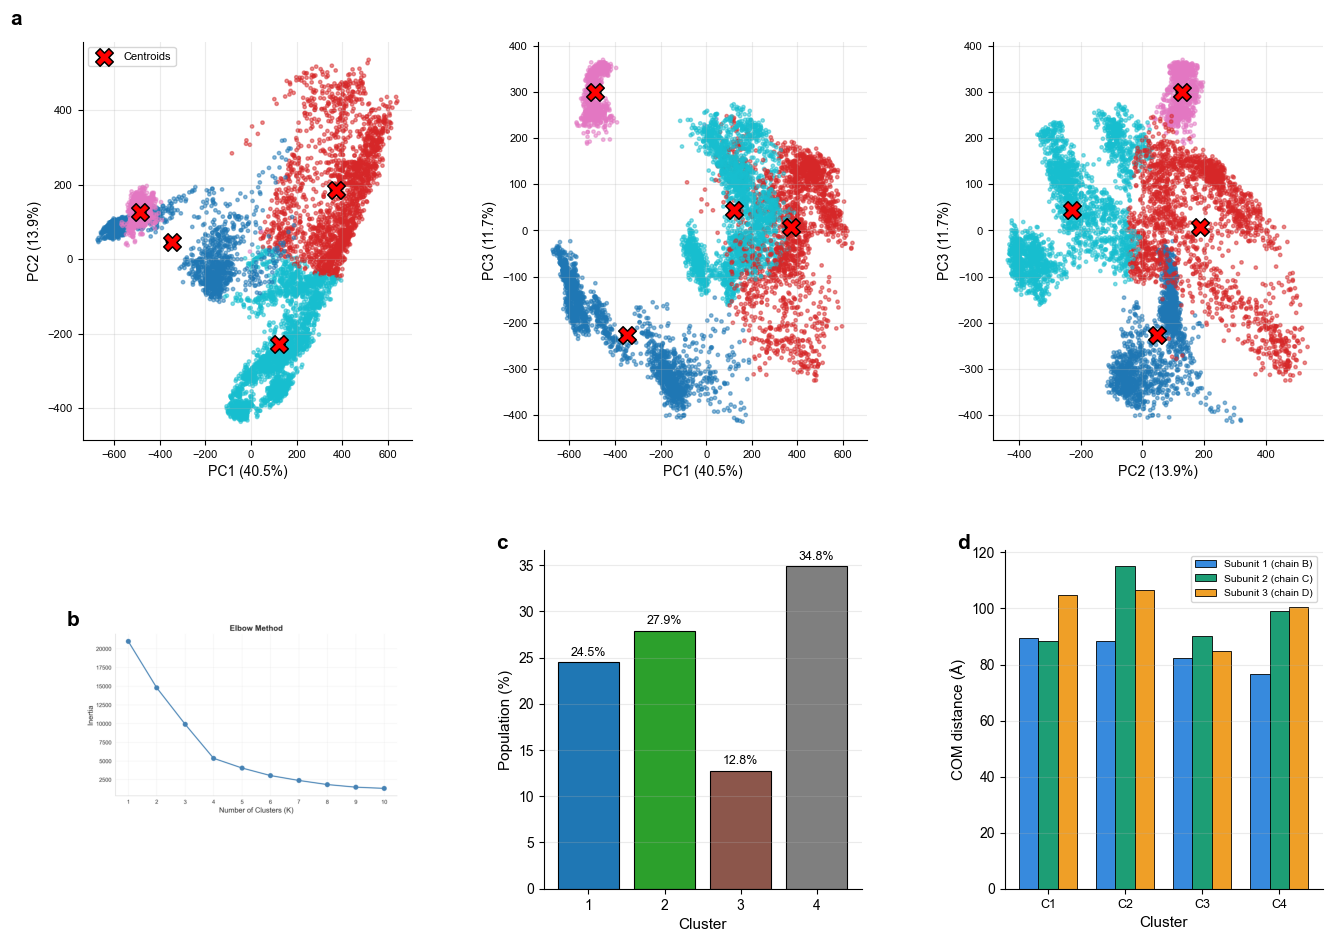

Saved: /Volumes/SAMSUNG/CESAproject/MD_after_docking/CESA1/result_CESA1_ClusPro/run/KMeans/Fig4_combined_4panel_v2.png


In [12]:
# ============================================================
# CELL — Combined figure: 3 PCA projections (a), elbow (b),
# populations (c), COM distance (d)
# Panel (a) shows PC1-PC2, PC1-PC3, PC2-PC3 because all three PCs
# contribute meaningfully to cluster separation (between/within
# variance ratios: PC1=8.16, PC2=3.22, PC3=4.80) — none can be dropped
# without losing real separation information.
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from pathlib import Path
from matplotlib import rcParams

rcParams['font.family']  = 'Arial'
rcParams['pdf.fonttype'] = 42

KMEANS_DIR = Path('/Volumes/SAMSUNG/CESAproject/MD_after_docking/CESA1/result_CESA1_ClusPro/run/KMeans')
RUN_DIR    = KMEANS_DIR.parent
COM_CSV    = RUN_DIR / 'ContactMap' / 'hvglu3_com_distance_by_cluster.csv'

n_clusters = 4
cluster_colors = [plt.cm.tab10(i / n_clusters) for i in range(n_clusters)]

data1     = pd.read_csv(KMEANS_DIR / 'PCA_clusters.csv')
explained = [40.5, 13.9, 11.7]   # PC1, PC2, PC3 percent variance explained — update if different
centers   = data1.groupby('Cluster')[['PC1', 'PC2', 'PC3']].mean().values
pc_idx    = {'PC1': 0, 'PC2': 1, 'PC3': 2}

fig = plt.figure(figsize=(16, 11))
outer = gridspec.GridSpec(2, 1, height_ratios=[1, 0.85], hspace=0.30)

# ══════════════════════════════════════════════
# Top row — Panel (a): three pairwise PCA projections
# ══════════════════════════════════════════════
top = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[0], wspace=0.38)
pc_pairs = [('PC1', 'PC2'), ('PC1', 'PC3'), ('PC2', 'PC3')]

for j, (xkey, ykey) in enumerate(pc_pairs):
    ax = fig.add_subplot(top[j])
    xi, yi = pc_idx[xkey], pc_idx[ykey]
    ax.scatter(
        data1[xkey], data1[ykey],
        c=data1['Cluster'], cmap='tab10',
        vmin=0, vmax=n_clusters - 1,
        s=6, alpha=0.5
    )
    ax.scatter(
        centers[:, xi], centers[:, yi],
        c='red', s=160, marker='X',
        edgecolors='black', linewidths=1.1,
        label='Centroids' if j == 0 else None, zorder=5
    )
    for i, c in enumerate(centers):
        ax.text(c[xi], c[yi], f'C{i+1}', fontsize=8, weight='bold',
                ha='center', va='center')

    ax.set_xlabel(f'{xkey} ({explained[xi]}%)', fontsize=10)
    ax.set_ylabel(f'{ykey} ({explained[yi]}%)', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=8)
    if j == 0:
        ax.legend(fontsize=8, loc='upper left')
        ax.text(-0.22, 1.08, 'a', transform=ax.transAxes,
                fontsize=15, weight='bold', va='top')

# ══════════════════════════════════════════════
# Bottom row — Panels (b) elbow, (c) populations, (d) COM distance
# ══════════════════════════════════════════════
bottom = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[1], wspace=0.45)

# Panel (b) — Elbow plot (reused from saved image)
ax_b = fig.add_subplot(bottom[0])
elbow_img = mpimg.imread(KMEANS_DIR / 'Elbow_plot.png')
ax_b.imshow(elbow_img)
ax_b.axis('off')
ax_b.text(-0.05, 1.05, 'b', transform=ax_b.transAxes,
          fontsize=15, weight='bold', va='top')

# Panel (c) — Cluster population bar chart (rebuilt natively)
ax_c = fig.add_subplot(bottom[1])
population = data1['Cluster'].value_counts().sort_index()
pct = (population.values / len(data1) * 100)

bars = ax_c.bar(
    population.index + 1, pct,
    color=cluster_colors, edgecolor='black', linewidth=0.8
)
for bar, p in zip(bars, pct):
    ax_c.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
              f'{p:.1f}%', ha='center', va='bottom', fontsize=9)

ax_c.set_xlabel('Cluster', fontsize=11)
ax_c.set_ylabel('Population (%)', fontsize=11)
ax_c.set_xticks(population.index + 1)
ax_c.spines['top'].set_visible(False)
ax_c.spines['right'].set_visible(False)
ax_c.grid(axis='y', alpha=0.25)
ax_c.text(-0.15, 1.05, 'c', transform=ax_c.transAxes,
          fontsize=15, weight='bold', va='top')

# Panel (d) — HvGLU3-to-subunit COM distance by cluster
ax_d = fig.add_subplot(bottom[2])
com_df = pd.read_csv(COM_CSV)
com_df = com_df.set_index('Cluster') if 'Cluster' in com_df.columns else com_df.set_index(com_df.columns[0])

x = np.arange(n_clusters)
width = 0.25
subunit_cols = [c for c in com_df.columns if 'subunit' in c.lower()]
subunit_labels = ['Subunit 1 (chain B)', 'Subunit 2 (chain C)', 'Subunit 3 (chain D)']
subunit_face_colors = ['#378ADD', '#1D9E75', '#EF9F27']

for i, (col, lab, col_color) in enumerate(zip(subunit_cols, subunit_labels, subunit_face_colors)):
    ax_d.bar(x + (i - 1) * width, com_df[col].values, width,
             label=lab, color=col_color, edgecolor='black', linewidth=0.6)

ax_d.set_xlabel('Cluster', fontsize=11)
ax_d.set_ylabel('COM distance (Å)', fontsize=11)
ax_d.set_xticks(x)
ax_d.set_xticklabels([f'C{i+1}' for i in range(n_clusters)], fontsize=9)
ax_d.legend(fontsize=7.5, loc='upper right')
ax_d.spines['top'].set_visible(False)
ax_d.spines['right'].set_visible(False)
ax_d.grid(axis='y', alpha=0.25)
ax_d.text(-0.15, 1.05, 'd', transform=ax_d.transAxes,
          fontsize=15, weight='bold', va='top')

out_path = KMEANS_DIR / 'Fig4_combined_4panel_v2.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(KMEANS_DIR / 'Fig4_combined_4panel_v2.pdf', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved: {out_path}')

In [4]:
# ── Merge with cluster assignment using row index as frame number ──
df_clusters = df_clusters.reset_index().rename(columns={'index': 'frame'})
df_clusters['Cluster'] = df_clusters['Cluster'] + 1   # convert 0-indexed -> 1-indexed (Cluster 1-4)

df_merged = df_dist.merge(df_clusters[['frame', 'Cluster']], on='frame', how='inner')
print(f'Merged: {len(df_merged)} frames with both distance + cluster')
print(df_merged['Cluster'].value_counts().sort_index())

# ── Summarize: mean COM distance per cluster per subunit ──
summary = df_merged.groupby('Cluster')[['subunit1_B','subunit2_C','subunit3_D']].mean().round(2)
print('\n=== Mean HvGLU3-to-subunit COM distance (Å) by cluster ===')
print(summary)

summary.to_csv(RUN_DIR / 'ContactMap' / 'hvglu3_com_distance_by_cluster.csv')
print('\n✅ Saved summary CSV')

Merged: 6996 frames with both distance + cluster
Cluster
1    1714
2    1952
3     892
4    2438
Name: count, dtype: int64

=== Mean HvGLU3-to-subunit COM distance (Å) by cluster ===
         subunit1_B  subunit2_C  subunit3_D
Cluster                                    
1             89.60       88.56      104.79
2             88.28      115.01      106.51
3             82.38       90.30       84.66
4             76.66       98.96      100.45

✅ Saved summary CSV


In [8]:
# Check how much each PC contributes to cluster separation vs within-cluster spread
for pc in ['PC1', 'PC2', 'PC3']:
    between_var = data1.groupby('Cluster')[pc].mean().var()
    within_var  = data1.groupby('Cluster')[pc].var().mean()
    print(f'{pc}: between-cluster variance = {between_var:.1f}, within-cluster variance = {within_var:.1f}, ratio = {between_var/within_var:.2f}')

PC1: between-cluster variance = 160836.0, within-cluster variance = 19712.1, ratio = 8.16
PC2: between-cluster variance = 33428.5, within-cluster variance = 10397.4, ratio = 3.22
PC3: between-cluster variance = 46558.1, within-cluster variance = 9702.5, ratio = 4.80
